In [ ]:
!pip uninstall scikit-learn -y
!pip install scikit-learn

Found existing installation: scikit-learn 1.7.0
Uninstalling scikit-learn-1.7.0:
  Successfully uninstalled scikit-learn-1.7.0
  Using cached scikit_learn-1.7.0-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (17 kB)
Using cached scikit_learn-1.7.0-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (12.9 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sklearn-compat 0.1.3 requires scikit-learn<1.7,>=1.2, but you have scikit-learn 1.7.0 which is incompatible.


In [ ]:
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense

bikes = pd.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes.csv')
bikes

# instant: record index
# dteday : date  --- split into day, month, year
# hr : hour (0 to 23)   ---split into AM/PM
# casual: count of casual users
# registered: count of registered users   --- / casual by registered to get new and returning users
# temp_c : temperature in Celsius.  ---change to F
# feels_like_c: "Feels like" temperature in Celsius.  ---change to F
# hum: humidity percentage  ---change to actual percent
# windspeed: Wind speed.
# weathersit :    ---one hot encode!!!
  # 1: Clear, Few clouds, Partly cloudy, Partly cloudy
  # 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
  # 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
  # 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog
# season : season (1:winter, 2:spring, 3:summer, 4:fall)   ---one hot encode!!!
# holiday : weather day is holiday or not
# workingday : if day is neither weekend nor holiday is 1, otherwise is 0.

,dteday,hr,casual,registered,temp_c,feels_like_c,hum,windspeed,weathersit,season,holiday,workingday
0,1/1/2011,0.0,3,13,3.0,3.0,0.7957,0.8,1,1,0,0
1,1/1/2011,1.0,8,30,1.7,1.7,0.8272,0.8,1,1,0,0
2,1/1/2011,2.0,5,26,1.9,1.9,0.8157,1.1,1,1,0,0
3,1/1/2011,3.0,3,9,2.5,2.5,0.7831,0.8,1,1,0,0
4,1/1/2011,4.0,0,1,2.0,2.0,0.8075,1.1,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
112470,10/31/2023,19.0,241,594,10.2,10.2,0.4516,8.4,2,4,0,1
112471,10/31/2023,20.0,171,450,8.9,7.5,0.5268,9.3,1,4,0,1
112472,10/31/2023,21.0,176,402,7.7,6.4,0.5756,7.8,1,4,0,1
112473,10/31/2023,22.0,106,257,8.0,8.0,0.5604,0.0,1,4,0,1


In [ ]:
bikes.describe()

,hr,casual,registered,temp_c,feels_like_c,hum,windspeed,weathersit,season,holiday,workingday
count,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000
mean,11.501098,90.434612,249.193625,15.376487,14.659325,0.636624,13.100614,1.405441,2.495799,0.030300,0.684312
std,6.921864,128.655621,258.267544,9.749467,11.428324,0.190328,7.857600,0.683450,1.101152,0.171412,0.464791
min,0.000000,0.000000,0.000000,-14.700000,-24.000000,0.088900,0.000000,1.000000,1.000000,0.000000,0.000000
25%,6.000000,7.000000,48.000000,7.600000,5.400000,0.484100,7.700000,1.000000,2.000000,0.000000,0.000000
50%,12.000000,36.000000,180.000000,16.000000,16.000000,0.640900,12.200000,1.000000,2.000000,0.000000,1.000000
75%,18.000000,122.000000,360.000000,23.500000,23.500000,0.798800,17.500000,2.000000,3.000000,0.000000,1.000000
max,23.000000,1244.000000,1702.000000,40.500000,49.600000,1.000000,69.800000,4.000000,4.000000,1.000000,1.000000


In [ ]:
bicycles = bikes
bicycles['season'] = bicycles['season'].map({1:"Winter", 2:"Spring", 3:"Summer", 4:"Fall"})
bicycles['weathersit'] = bicycles['weathersit'].map({1:"Clear", 2:"Mist", 3:"Light Rain", 4:"Heavy Rain"})
bicycles = pd.get_dummies(bicycles, columns=['season', 'weathersit'], prefix='', prefix_sep='')
bicycles


,dteday,hr,casual,registered,temp_c,feels_like_c,hum,windspeed,holiday,workingday,Fall,Spring,Summer,Winter,Clear,Heavy Rain,Light Rain,Mist
0,1/1/2011,0.0,3,13,3.0,3.0,0.7957,0.8,0,0,False,False,False,True,True,False,False,False
1,1/1/2011,1.0,8,30,1.7,1.7,0.8272,0.8,0,0,False,False,False,True,True,False,False,False
2,1/1/2011,2.0,5,26,1.9,1.9,0.8157,1.1,0,0,False,False,False,True,True,False,False,False
3,1/1/2011,3.0,3,9,2.5,2.5,0.7831,0.8,0,0,False,False,False,True,True,False,False,False
4,1/1/2011,4.0,0,1,2.0,2.0,0.8075,1.1,0,0,False,False,False,True,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112470,10/31/2023,19.0,241,594,10.2,10.2,0.4516,8.4,0,1,True,False,False,False,False,False,False,True
112471,10/31/2023,20.0,171,450,8.9,7.5,0.5268,9.3,0,1,True,False,False,False,True,False,False,False
112472,10/31/2023,21.0,176,402,7.7,6.4,0.5756,7.8,0,1,True,False,False,False,True,False,False,False
112473,10/31/2023,22.0,106,257,8.0,8.0,0.5604,0.0,0,1,True,False,False,False,True,False,False,False


In [ ]:
from sklearn.model_selection import train_test_split

X = bicycles.drop(columns=["registered","dteday"])
y = bicycles.registered
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=35)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# fit scaler on training data
norm = MinMaxScaler().fit(X_train)

# transform training data
X_train = norm.transform(X_train)

# transform testing dataabs
X_test = norm.transform(X_test)

In [ ]:
model = Sequential()
model.add(Dense(128, input_dim=len(X_train[0]), activation='sigmoid'))
model.add(Dropout(.5))
model.add(Dense(256, activation='relu'))
model.add(Dense(64, activation='leaky_relu'))

model.add(Dense(1, activation='relu'))
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,713 (202.00 KB)

 Trainable params: 51,713 (202.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
opt = keras.optimizers.Adam()
model.compile(loss="mean_squared_error", optimizer=opt, metrics=['mse'])

early_stop = keras.callbacks.EarlyStopping(monitor='val_mse', patience=30)

history = model.fit(X_train, y_train, epochs=5, validation_split=.35, batch_size=20, callbacks=[early_stop],shuffle=False)

hist = pd.DataFrame(history.history)
hist

Epoch 1/5
2559/2559 ━━━━━━━━━━━━━━━━━━━━ 27s 9ms/step - loss: 65652.6562 - mse: 65652.6562 - val_loss: 45595.5508 - val_mse: 45595.5508
Epoch 2/5
2559/2559 ━━━━━━━━━━━━━━━━━━━━ 27s 4ms/step - loss: 48179.1875 - mse: 48179.1875 - val_loss: 43342.0312 - val_mse: 43342.0312
Epoch 3/5
2559/2559 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 46209.7109 - mse: 46209.7109 - val_loss: 42476.9102 - val_mse: 42476.9102
Epoch 4/5
2559/2559 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - loss: 44984.0938 - mse: 44984.0898 - val_loss: 42125.3398 - val_mse: 42125.3398
Epoch 5/5
2559/2559 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 44437.8203 - mse: 44437.8203 - val_loss: 41485.6484 - val_mse: 41485.6484


,loss,mse,val_loss,val_mse
0,56862.449219,56862.449219,45595.550781,45595.550781
1,46796.113281,46796.113281,43342.031250,43342.031250
2,45292.339844,45292.339844,42476.910156,42476.910156
3,44299.761719,44299.761719,42125.339844,42125.339844
4,43863.359375,43863.359375,41485.648438,41485.648438


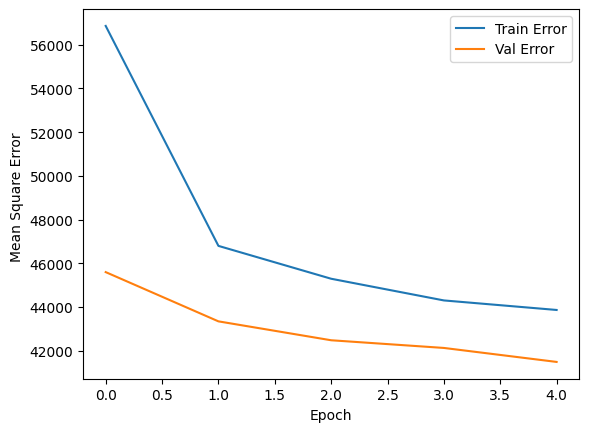

In [ ]:
hist = hist.reset_index()
def plot_history():
    plt.figure()
    plt.xlabel('Epoch')
    plt.ylabel('Mean Square Error ')
    plt.plot(hist['index'], hist['mse'], label='Train Error')
    plt.plot(hist['index'], hist['val_mse'], label = 'Val Error')
    plt.legend()
    # plt.ylim([0,50])

plot_history()

In [ ]:
predictions = np.round(model.predict(X_test),1)
predictions

1055/1055 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


array([[390.9],
       [316. ],
       [157.3],
       ...,
       [443.6],
       [351.6],
       [250.4]], shape=(33743, 1), dtype=float32)

In [ ]:
from sklearn.metrics import root_mean_squared_error, r2_score

result = root_mean_squared_error(y_test, predictions)
print(result)

r2 = r2_score(y_test,predictions)
print(r2)

202.98074340820312
0.3769350051879883


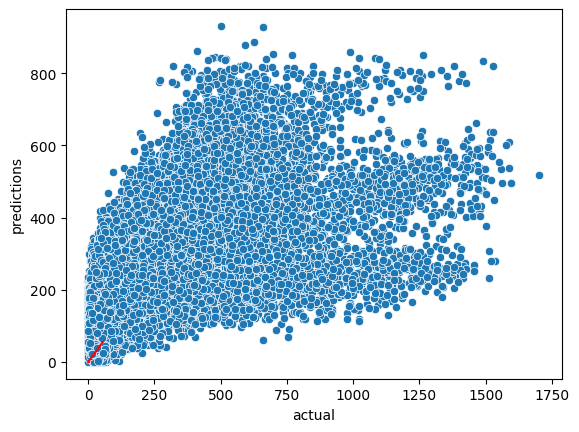

In [ ]:
pred = pd.DataFrame(predictions,columns=['predictions'])
pred
pred['actual'] = y_test.tolist()
pred

pred['difference'] = pred['actual']-pred['predictions']
pred

import seaborn as sns
xlims =(0,55)
ax = sns.scatterplot(data=pred,x='actual',y='predictions')
ax.plot(xlims,xlims, color='r')
plt.show()

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam, RMSprop
!pip install --upgrade scikeras
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV

# Define the function to create the model
def create_model(optimizer='adam', dropout_rate=0.5, activation='relu'):
    model = Sequential()
    model.add(Input(shape=(len(X_train[0]),)))  # Use Input layer instead of input_dim
    model.add(Dense(128, activation=activation))
    model.add(Dropout(dropout_rate))
    model.add(Dense(256, activation=activation))
    model.add(Dense(64, activation='leaky_relu'))
    model.add(Dense(1, activation='relu'))
    model.compile(loss='mse', optimizer=optimizer)
    return model

# Wrap the model with KerasRegressor for compatibility with GridSearchCV
model = KerasRegressor(model=create_model, verbose=1)

# Define the grid of hyperparameters
param_grid = {
    # 'model__optimizer': ['adam', 'rmsprop'],
    'model__dropout_rate': [0.3, 0.5, 0.7],
    'model__activation': ['relu', 'tanh'],
    'batch_size': [16, 32, 64],
    'epochs': [3]  # You can reduce the number of epochs to speed up testing
}

# Set up GridSearchCV
grid = GridSearchCV(estimator=model, param_grid=param_grid, scoring='neg_mean_squared_error', cv=3)

# Execute the grid search
grid_result = grid.fit(X_train, y_train)

# Output the best parameters and score
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))

Epoch 1/3
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - loss: 51017.5938
Epoch 2/3
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - loss: 35729.9492
Epoch 3/3
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 32527.1621
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
Epoch 1/3
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - loss: 51724.5977
Epoch 2/3
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - loss: 34457.3398
Epoch 3/3
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 32709.3730
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
Epoch 1/3
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - loss: 51214.6914
Epoch 2/3
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - loss: 35849.9961
Epoch 3/3
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - loss: 32521.1562
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
Epoch 1/3
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - loss: 51681.1133
Epoch 2/3
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - loss: 36335.1445
Epoch 3/3
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 34999.5195
1

In [ ]:
# Get the best hyperparameters from the grid search
best_params = grid_result.best_params_

# Recreate the model with the best parameters
final_model = create_model(
    dropout_rate=best_params['model__dropout_rate'],
    activation=best_params['model__activation']
)
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15,restore_best_weights=True,mode='min')

# Train the model for 300 epochs with the best parameters
final_model.fit(X_train, y_train, epochs=5, batch_size=best_params['batch_size'],validation_split=.35,  verbose=1, callbacks=[early_stop])

Epoch 1/5
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 16s 4ms/step - loss: 54776.8828 - val_loss: 35066.7969
Epoch 2/5
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 23s 5ms/step - loss: 35238.3867 - val_loss: 29258.5527
Epoch 3/5
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - loss: 28355.3418 - val_loss: 20615.1309
Epoch 4/5
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - loss: 22176.8926 - val_loss: 18356.7500
Epoch 5/5
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - loss: 20375.7148 - val_loss: 16865.2812


In [ ]:
result = root_mean_squared_error(y_test, predictions)
print(result)

r2 = r2_score(y_test,predictions)
print(r2)

202.98074340820312
0.3769350051879883


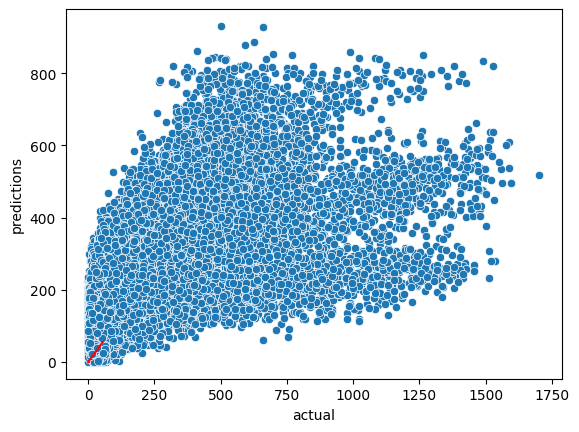

In [ ]:
pred = pd.DataFrame(predictions,columns=['predictions'])
pred
pred['actual'] = y_test.tolist()
pred

pred['difference'] = pred['actual']-pred['predictions']
pred

import seaborn as sns
xlims =(0,55)
ax = sns.scatterplot(data=pred,x='actual',y='predictions')
ax.plot(xlims,xlims, color='r')
plt.show()